In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm

data = pd.read_csv("alligator.txt", sep =r"\s+")

x = data["length"]
y = data["weight"]

data

,weight,length
0,130,94
1,51,74
2,640,147
3,28,58
4,80,86
5,110,94
6,33,63
7,90,86
8,36,69
9,38,72


In [10]:
def analisar_regressao(x, y, titulo, nome_x, nome_y):
    X = sm.add_constant(x)
    resultado = sm.OLS(y, X).fit()

    print(resultado.summary())

    # Previsões ao longo do intervalo observado
    x_grade = np.linspace(x.min(), x.max(), 200)
    X_grade = sm.add_constant(x_grade)

    tabela = resultado.get_prediction(
        X_grade
    ).summary_frame(alpha=0.05)

    residuos = resultado.resid

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    # Dispersão, reta e intervalos
    ax = axes[0, 0]

    ax.scatter(x, y, color="black", label="Dados", zorder=3)

    ax.fill_between(
        x_grade,
        tabela["obs_ci_lower"].to_numpy(),
        tabela["obs_ci_upper"].to_numpy(),
        color="gray",
        alpha=0.25,
        label="Predição de 95%"
    )

    ax.fill_between(
        x_grade,
        tabela["mean_ci_lower"].to_numpy(),
        tabela["mean_ci_upper"].to_numpy(),
        color="royalblue",
        alpha=0.25,
        label="Confiança de 95%"
    )

    ax.plot(
        x_grade,
        tabela["mean"].to_numpy(),
        color="blue",
        label="Reta estimada"
    )

    ax.set(
        title="Dispersão e regressão",
        xlabel=nome_x,
        ylabel=nome_y
    )

    ax.legend()

    # Residuos X preditos
    ax = axes[0, 1]

    ax.scatter(resultado.fittedvalues, residuos, color="black")
    ax.axhline(0, color="red", linestyle="--")

    ax.set(
        title="Resíduos versus preditos",
        xlabel=f"Valores preditos de {nome_y}",
        ylabel="Resíduo"
    )

    # Histograma e densidade normal de referência
    ax = axes[1, 0]

    ax.hist(
        residuos,
        bins="auto",
        density=True,
        color="steelblue",
        edgecolor="white",
        alpha=0.7
    )

    desvio = np.std(residuos, ddof=1)
    grade_residuos = np.linspace(
        residuos.min() - desvio,
        residuos.max() + desvio,
        200
    )

    ax.plot(
        grade_residuos,
        norm.pdf(
            grade_residuos,
            loc=np.mean(residuos),
            scale=desvio
        ),
        color="red",
        label="Normal de referência"
    )

    ax.set(
        title="Histograma dos resíduos",
        xlabel="Resíduo",
        ylabel="Densidade"
    )

    ax.legend()

    # QQ-plot
    sm.qqplot(residuos, line="s", ax=axes[1, 1])

    axes[1, 1].set(
        title="QQ-plot dos resíduos",
        xlabel="Quantis teóricos da normal padrão",
        ylabel="Quantis dos resíduos"
    )

    for ax in axes.flat:
        ax.grid(alpha=0.2)

    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

    return resultado

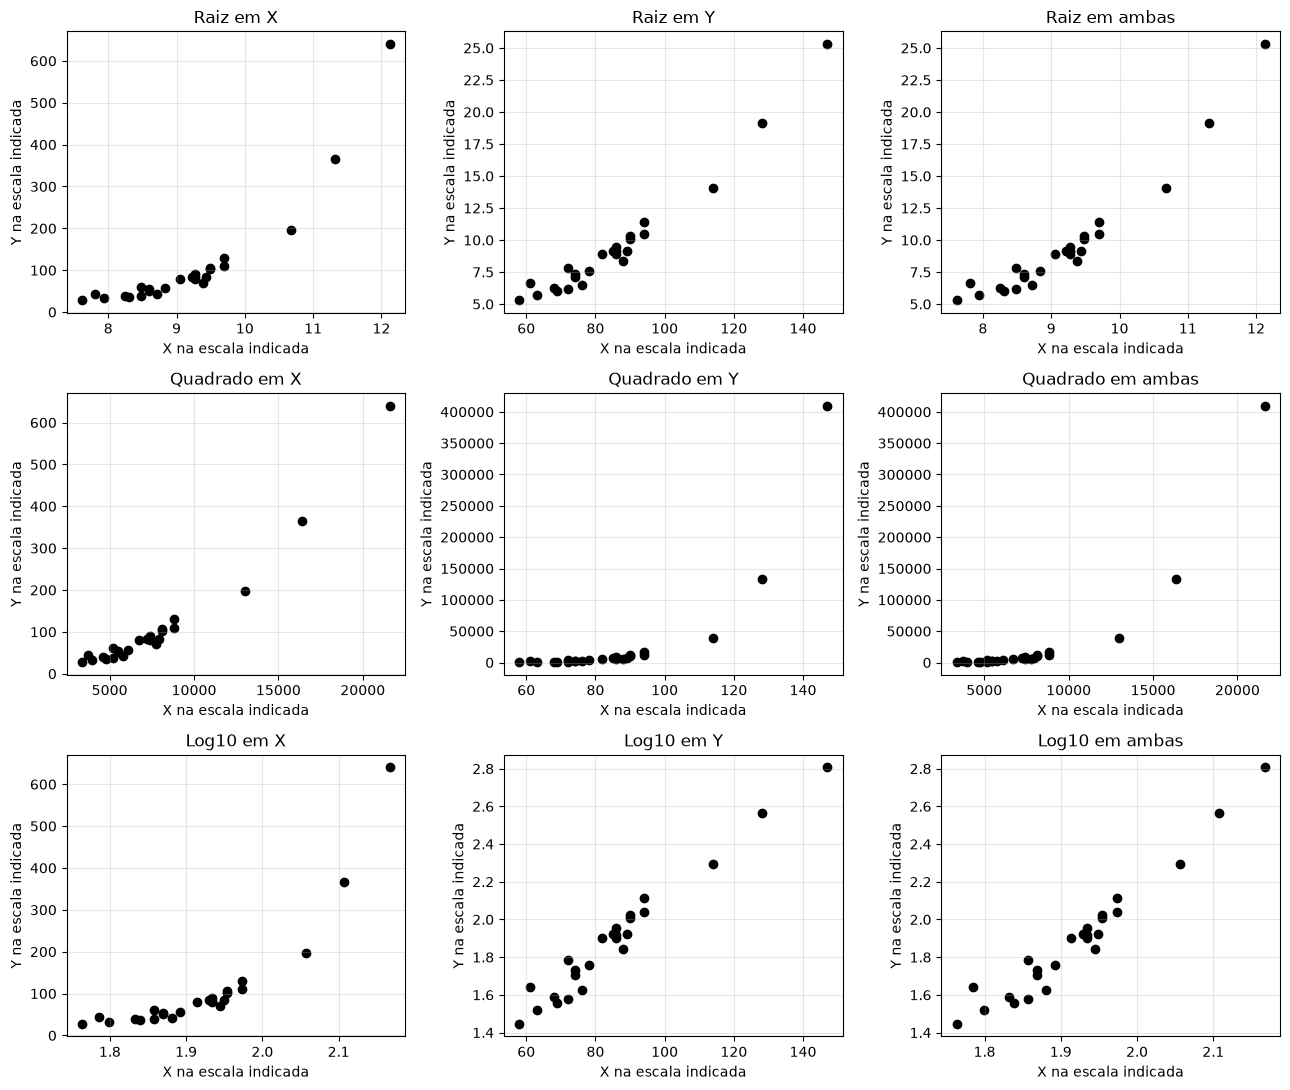

In [12]:
transformacoes = [
    ("Raiz em X", np.sqrt(x), y),
    ("Raiz em Y", x, np.sqrt(y)),
    ("Raiz em ambas", np.sqrt(x), np.sqrt(y)),

    ("Quadrado em X", x ** 2, y),
    ("Quadrado em Y", x, y ** 2),
    ("Quadrado em ambas", x ** 2, y ** 2),

    ("Log10 em X", np.log10(x), y),
    ("Log10 em Y", x, np.log10(y)),
    ("Log10 em ambas", np.log10(x), np.log10(y))
]

fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for ax, (nome, x_transformado, y_transformado) in zip(
    axes.flat, transformacoes
):
    ax.scatter(x_transformado, y_transformado, color="black")
    ax.set_title(nome)
    ax.set_xlabel("X na escala indicada")
    ax.set_ylabel("Y na escala indicada")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm

data = pd.read_csv("alligator.txt", sep=r"\s+")

x = data["length"]
y = data["weight"]

display(data.head())
print(data.isna().sum())

,weight,length
0,130,94
1,51,74
2,640,147
3,28,58
4,80,86


weight    0
length    0
dtype: int64


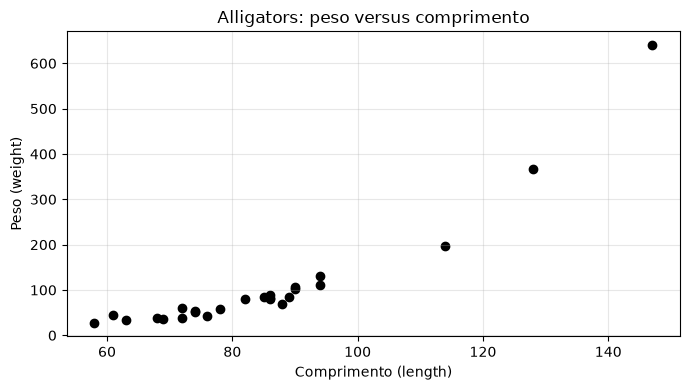

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(x, y, color="black")

ax.set(
    title="Alligators: peso versus comprimento",
    xlabel="Comprimento (length)",
    ylabel="Peso (weight)"
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
def analisar_regressao(x, y, titulo):
    X = sm.add_constant(x)
    resultado = sm.OLS(y, X).fit()

    print(resultado.summary())

    grade = np.linspace(x.min(), x.max(), 200)
    X_grade = sm.add_constant(grade)

    previsoes = resultado.get_prediction(
        X_grade
    ).summary_frame(alpha=0.05)

    residuos = resultado.resid

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    # Dados, reta e intervalos
    ax = axes[0, 0]

    ax.scatter(x, y, color="black", zorder=3)

    ax.fill_between(
        grade,
        previsoes["obs_ci_lower"].to_numpy(),
        previsoes["obs_ci_upper"].to_numpy(),
        color="gray",
        alpha=0.25,
        label="Predição de 95%"
    )

    ax.fill_between(
        grade,
        previsoes["mean_ci_lower"].to_numpy(),
        previsoes["mean_ci_upper"].to_numpy(),
        color="royalblue",
        alpha=0.25,
        label="Confiança de 95%"
    )

    ax.plot(
        grade,
        previsoes["mean"].to_numpy(),
        color="blue",
        label="Reta estimada"
    )

    ax.set(
        title="Ajuste da regressão",
        xlabel=x.name,
        ylabel=y.name
    )
    ax.legend()

    # Resíduos versus preditos
    ax = axes[0, 1]

    ax.scatter(resultado.fittedvalues, residuos, color="black")
    ax.axhline(0, color="red", linestyle="--")

    ax.set(
        title="Resíduos versus preditos",
        xlabel=f"Valores preditos de {y.name}",
        ylabel="Resíduo"
    )

    # Histograma e normal de referência
    ax = axes[1, 0]

    ax.hist(
        residuos,
        bins="auto",
        density=True,
        color="steelblue",
        edgecolor="white",
        alpha=0.7
    )

    media = residuos.mean()
    desvio = residuos.std(ddof=1)

    pontos = np.linspace(
        min(residuos.min(), media - 3 * desvio),
        max(residuos.max(), media + 3 * desvio),
        200
    )

    ax.plot(
        pontos,
        norm.pdf(pontos, loc=media, scale=desvio),
        color="red",
        label="Normal de referência"
    )

    ax.set(
        title="Histograma dos resíduos",
        xlabel="Resíduo",
        ylabel="Densidade"
    )
    ax.legend()

    # QQ-plot
    sm.qqplot(residuos, line="s", ax=axes[1, 1])
    axes[1, 1].set_title("QQ-plot dos resíduos")

    for ax in axes.flat:
        ax.grid(alpha=0.2)

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

    return resultado

                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     117.4
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.65e-10
Time:                        21:46:55   Log-Likelihood:                -134.16
No. Observations:                  25   AIC:                             272.3
Df Residuals:                      23   BIC:                             274.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -393.2640     47.534     -8.273      0.0

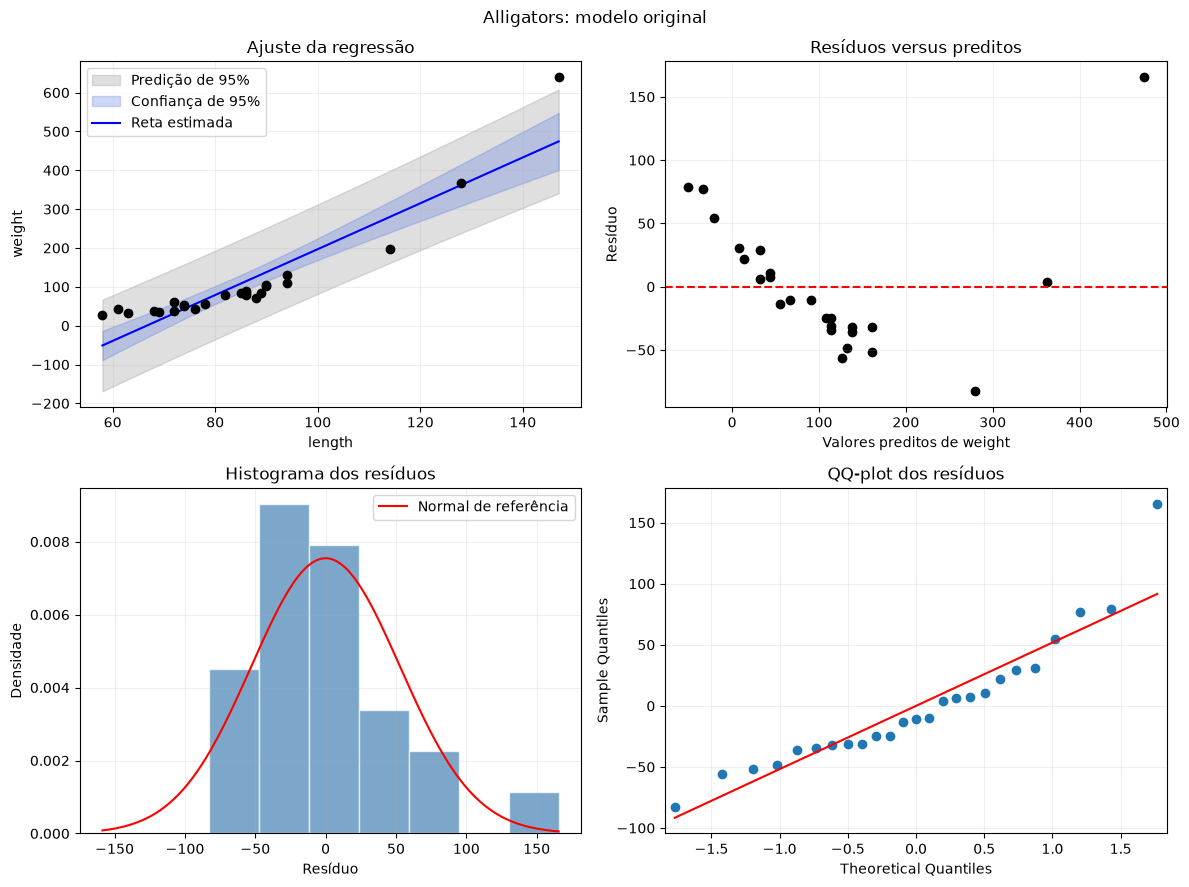

In [16]:
resultado_original = analisar_regressao(
    x,
    y,
    "Alligators: modelo original"
)

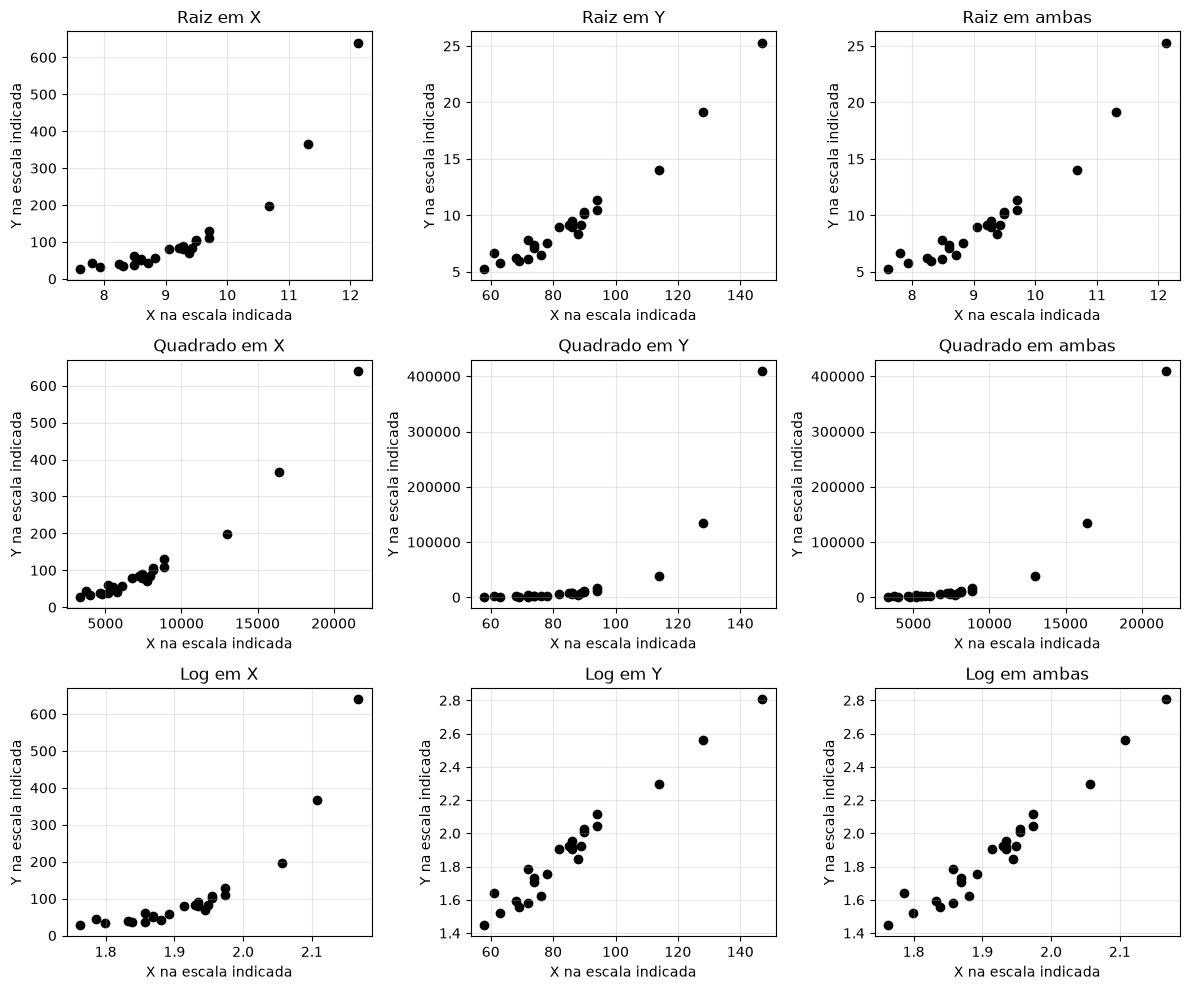

In [17]:
transformacoes = [
    ("Raiz em X", np.sqrt(x), y),
    ("Raiz em Y", x, np.sqrt(y)),
    ("Raiz em ambas", np.sqrt(x), np.sqrt(y)),

    ("Quadrado em X", x**2, y),
    ("Quadrado em Y", x, y**2),
    ("Quadrado em ambas", x**2, y**2),

    ("Log em X", np.log10(x), y),
    ("Log em Y", x, np.log10(y)),
    ("Log em ambas", np.log10(x), np.log10(y))
]

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for ax, (nome, x_transformado, y_transformado) in zip(
    axes.flat, transformacoes
):
    ax.scatter(x_transformado, y_transformado, color="black")
    ax.set_title(nome)
    ax.set_xlabel("X na escala indicada")
    ax.set_ylabel("Y na escala indicada")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

                            OLS Regression Results                            
Dep. Variable:          log10(weight)   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     394.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.59e-16
Time:                        21:47:15   Log-Likelihood:                 29.950
No. Observations:                  25   AIC:                            -55.90
Df Residuals:                      23   BIC:                            -53.46
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -4.4188      0.318    -13.907

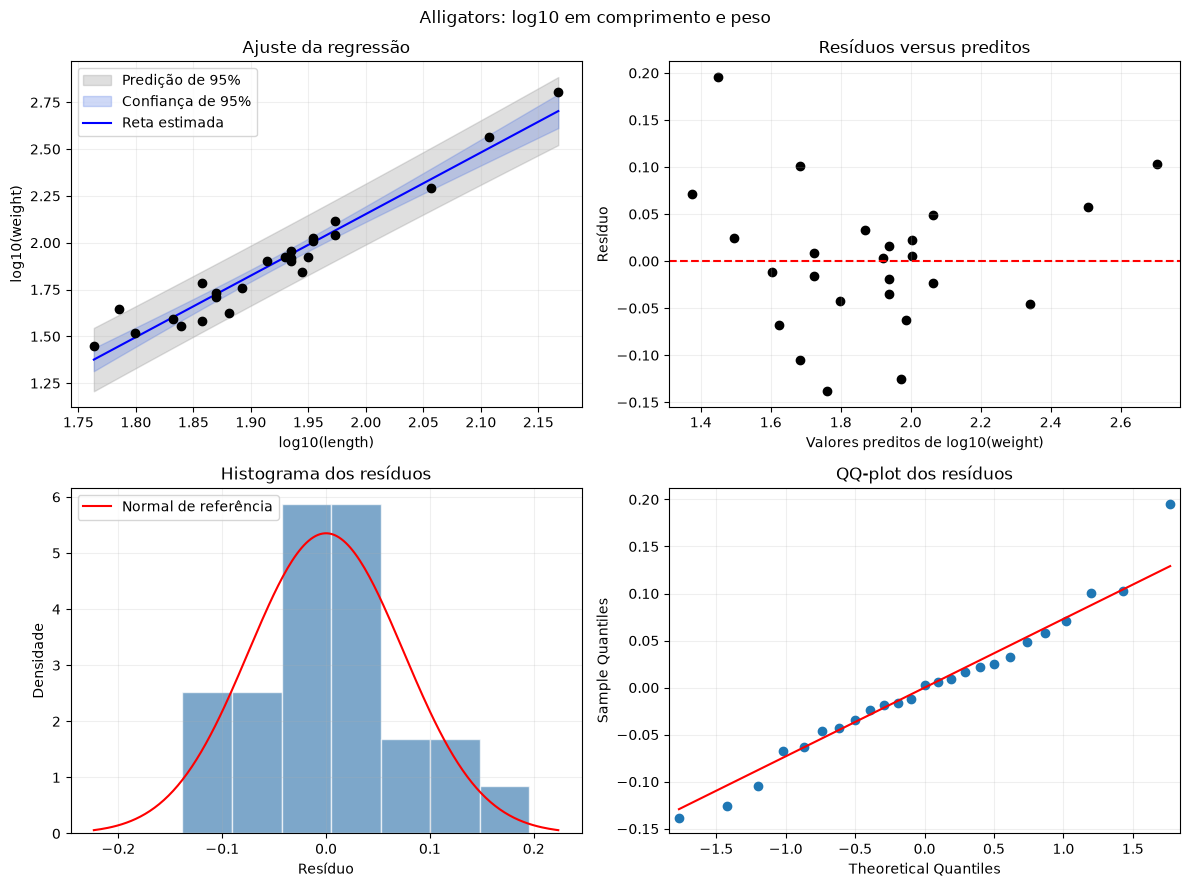

In [18]:
x_log = np.log10(x).rename("log10(length)")
y_log = np.log10(y).rename("log10(weight)")

resultado_log = analisar_regressao(
    x_log,
    y_log,
    "Alligators: log10 em comprimento e peso"
)